In [1]:
%pip install seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:

import re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
import seaborn as sns
warnings.filterwarnings("ignore")

In [6]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

FILE_NAME = r"C:\Users\SARAL\Desktop\FSK-Training"
DATA_PATH = Path(FILE_NAME)

if not DATA_PATH.exists():
    try:
        from google.colab import files
        print(f"Upload the Excel workbook: {FILE_NAME}")
        uploaded = files.upload()
        if uploaded:
            DATA_PATH = Path(next(iter(uploaded.keys())))
    except ImportError:
        pass

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find '{FILE_NAME}'. Put it beside this notebook or upload it in Colab."
    )

print("Using workbook:", DATA_PATH.resolve())

Using workbook: C:\Users\SARAL\Desktop\FSK-Training


In [7]:
raw = pd.read_excel(DATA_PATH, sheet_name=0, header=None, dtype=object)

def find_row_containing(frame, phrase):
    mask = frame.astype(str).apply(
        lambda col: col.str.contains(phrase, case=False, na=False)
    ).any(axis=1)
    matches = frame.index[mask].tolist()
    return matches[0] if matches else None

detail_header_row = find_row_containing(raw, "Cases Received At CM Grievance Cell")
total_row = find_row_containing(raw, "Total Pending Complaints")
nodal_section_row = find_row_containing(raw, "Pendency of Nodal Officer")

if detail_header_row is None or total_row is None or nodal_section_row is None:
    raise ValueError("Expected office-wise and nodal-officer sections were not found in the workbook.")

detail_headers = raw.iloc[detail_header_row].tolist()
detail = raw.iloc[detail_header_row + 1:total_row].copy()
detail.columns = detail_headers

# Keep only valid office rows; exclude blank and summary rows.
detail = detail.rename(columns={
    detail.columns[1]: "Office",
    detail.columns[2]: "Overdue",
    detail.columns[3]: "In_Action"
})
detail = detail[detail["Office"].notna()].copy()
detail["Office"] = detail["Office"].astype(str).str.strip()
detail = detail[detail["Office"].str.lower().ne("nan")]
for col in ["Overdue", "In_Action"]:
    detail[col] = pd.to_numeric(detail[col], errors="coerce")
detail = detail.dropna(subset=["Overdue", "In_Action"]).copy()
detail[["Overdue", "In_Action"]] = detail[["Overdue", "In_Action"]].astype(int)

# Read the workbook's stated total row for reconciliation.
stated_overdue = pd.to_numeric(raw.iloc[total_row, 2], errors="coerce")
stated_in_action = pd.to_numeric(raw.iloc[total_row, 3], errors="coerce")

# Parse nodal-officer table (header follows the section title).
nodal_header_row = find_row_containing(raw.iloc[nodal_section_row + 1:], "Nodal Officer")
if nodal_header_row is None or nodal_header_row <= nodal_section_row:
    nodal = pd.DataFrame(columns=["Nodal_Officer", "Total_Pending"])
else:
    nodal_headers = raw.iloc[nodal_header_row].tolist()
    nodal_raw = raw.iloc[nodal_header_row + 1:].copy()
    nodal_raw.columns = nodal_headers
    nodal = nodal_raw.iloc[:, [1, 3]].copy()
    nodal.columns = ["Nodal_Officer", "Total_Pending"]
    nodal["Nodal_Officer"] = nodal["Nodal_Officer"].astype(str).str.strip()
    nodal["Total_Pending"] = pd.to_numeric(nodal["Total_Pending"], errors="coerce")
    nodal = nodal.dropna(subset=["Total_Pending", "Nodal_Officer"]).copy()
    nodal = nodal[nodal["Nodal_Officer"].str.lower().ne("nan")]
    nodal["Total_Pending"] = nodal["Total_Pending"].astype(int)

print("Office-wise records:", len(detail))
print("Nodal-officer records:", len(nodal))
print("Office-wise row totals | Overdue:", detail["Overdue"].sum(),
      "| In-Action:", detail["In_Action"].sum())
print("Workbook stated totals | Overdue:", stated_overdue,
      "| In-Action:", stated_in_action)
print("\nOffice-wise data preview:")
display(detail.head())
print("\nNodal-officer data:")
display(nodal)

PermissionError: [Errno 13] Permission denied: 'C:\\Users\\SARAL\\Desktop\\FSK-Training'

In [9]:

from pathlib import Path

FOLDER_PATH = Path(r"C:\Users\SARAL\Desktop\FSK-Training")

# Option A: Specify the exact filename
DATA_PATH = FOLDER_PATH / "your_file_name.xlsx"

# Option B: Automatically pick the first .xlsx or .xls file in the folder
excel_files = list(FOLDER_PATH.glob("*.xlsx")) + list(FOLDER_PATH.glob("*.xls"))
if not excel_files:
    raise FileNotFoundError(f"No Excel files found in {FOLDER_PATH}")
DATA_PATH = excel_files[0]
print("Reading:", DATA_PATH)

Reading: C:\Users\SARAL\Desktop\FSK-Training\CM WINDOW NOVEMBER.xlsx


In [10]:
raw = pd.read_excel(DATA_PATH, sheet_name=0, header=None, dtype=object)

def find_row_containing(frame, phrase):
    mask = frame.astype(str).apply(
        lambda col: col.str.contains(phrase, case=False, na=False)
    ).any(axis=1)
    matches = frame.index[mask].tolist()
    return matches[0] if matches else None

detail_header_row = find_row_containing(raw, "Cases Received At CM Grievance Cell")
total_row = find_row_containing(raw, "Total Pending Complaints")
nodal_section_row = find_row_containing(raw, "Pendency of Nodal Officer")

if detail_header_row is None or total_row is None or nodal_section_row is None:
    raise ValueError("Expected office-wise and nodal-officer sections were not found in the workbook.")

detail_headers = raw.iloc[detail_header_row].tolist()
detail = raw.iloc[detail_header_row + 1:total_row].copy()
detail.columns = detail_headers

# Keep only valid office rows; exclude blank and summary rows.
detail = detail.rename(columns={
    detail.columns[1]: "Office",
    detail.columns[2]: "Overdue",
    detail.columns[3]: "In_Action"
})
detail = detail[detail["Office"].notna()].copy()
detail["Office"] = detail["Office"].astype(str).str.strip()
detail = detail[detail["Office"].str.lower().ne("nan")]
for col in ["Overdue", "In_Action"]:
    detail[col] = pd.to_numeric(detail[col], errors="coerce")
detail = detail.dropna(subset=["Overdue", "In_Action"]).copy()
detail[["Overdue", "In_Action"]] = detail[["Overdue", "In_Action"]].astype(int)

# Read the workbook's stated total row for reconciliation.
stated_overdue = pd.to_numeric(raw.iloc[total_row, 2], errors="coerce")
stated_in_action = pd.to_numeric(raw.iloc[total_row, 3], errors="coerce")

# Parse nodal-officer table (header follows the section title).
nodal_header_row = find_row_containing(raw.iloc[nodal_section_row + 1:], "Nodal Officer")
if nodal_header_row is None or nodal_header_row <= nodal_section_row:
    nodal = pd.DataFrame(columns=["Nodal_Officer", "Total_Pending"])
else:
    nodal_headers = raw.iloc[nodal_header_row].tolist()
    nodal_raw = raw.iloc[nodal_header_row + 1:].copy()
    nodal_raw.columns = nodal_headers
    nodal = nodal_raw.iloc[:, [1, 3]].copy()
    nodal.columns = ["Nodal_Officer", "Total_Pending"]
    nodal["Nodal_Officer"] = nodal["Nodal_Officer"].astype(str).str.strip()
    nodal["Total_Pending"] = pd.to_numeric(nodal["Total_Pending"], errors="coerce")
    nodal = nodal.dropna(subset=["Total_Pending", "Nodal_Officer"]).copy()
    nodal = nodal[nodal["Nodal_Officer"].str.lower().ne("nan")]
    nodal["Total_Pending"] = nodal["Total_Pending"].astype(int)

print("Office-wise records:", len(detail))
print("Nodal-officer records:", len(nodal))
print("Office-wise row totals | Overdue:", detail["Overdue"].sum(),
      "| In-Action:", detail["In_Action"].sum())
print("Workbook stated totals | Overdue:", stated_overdue,
      "| In-Action:", stated_in_action)
print("\nOffice-wise data preview:")
display(detail.head())
print("\nNodal-officer data:")
display(nodal)

ValueError: Expected office-wise and nodal-officer sections were not found in the workbook.

In [11]:
xl = pd.ExcelFile(DATA_PATH)
print("Sheet names:", xl.sheet_names)

# Inspect first 40 rows of sheet 0 with non-empty cells
for idx, row in raw.iloc[:40].iterrows():
    non_empty = [f"c{c}:{repr(v)}" for c, v in enumerate(row) if pd.notna(v) and str(v).strip() != ""]
    if non_empty:
        print(f"Row {idx}: " + " | ".join(non_empty))

Sheet names: ['Sheet1']
Row 0: c0:'Sr No' | c1:'Registration No' | c2:'Complaint relates to' | c3:'Registration Date' | c4:'Name' | c5:'Mobile' | c6:'Subject Details' | c7:'status'
Row 1: c0:1 | c1:'CMOFF/N/2026/132356' | c2:'JHAJJAR' | c3:'2026-11-26' | c4:'RAKESH KUMAR' | c5:8901680519 | c6:'Public Service delay शिकायत संख्या न cmoff/n/2023 /080358 को बिना जांच के बन्द किये जाने बारे' | c7:'BDPO MATANHAIL'
Row 2: c0:2 | c1:'CMOFF/N/2026/132250' | c2:'JHAJJAR' | c3:'2026-11-25' | c4:'SONIA' | c5:8950373991 | c6:'Allegation of corruption/malpractices Complaint regarding alleged demand for bribes and corruption through middlemen at Tehsil Bahadurgarh for getting Fancy Registration Number HR13Z9900 allotted to my scooter.' | c7:'S.D.M Bahadurgarh'
Row 3: c0:3 | c1:'CMOFF/N/2026/131765' | c2:'JHAJJAR' | c3:'2026-11-25' | c4:'Jeet Singh' | c5:9416445914 | c6:'Public Service delay दरखास्त बाबत किये जाने कार्यवाही बारे' | c7:'Tehsildar Jhajjar'
Row 4: c0:4 | c1:'CMOFF/N/2026/131278' | c2:'JH

In [12]:
def find_row_containing(frame, phrase):
    target = " ".join(phrase.lower().split())
    normalized = frame.astype(str).apply(
        lambda col: col.str.replace(r"\s+", " ", regex=True).str.strip().str.lower()
    )
    mask = normalized.apply(lambda col: col.str.contains(target, regex=False, na=False)).any(axis=1)
    matches = frame.index[mask].tolist()
    return matches[0] if matches else None

In [13]:
nodal_header_row = find_row_containing(raw.loc[nodal_section_row + 1:], "Nodal Officer")
if nodal_header_row is None:
    nodal = pd.DataFrame(columns=["Nodal_Officer", "Total_Pending"])
else:
    nodal_headers = raw.loc[nodal_header_row].tolist()
    nodal_pos = raw.index.get_loc(nodal_header_row)
    nodal_raw = raw.iloc[nodal_pos + 1:].copy()

TypeError: unsupported operand type(s) for +: 'NoneType' and 'int'

In [14]:
if nodal_section_row is None:
    print("Warning: 'Pendency of Nodal Officer' section not found.")
    nodal = pd.DataFrame(columns=["Nodal_Officer", "Total_Pending"])
else:
    nodal_header_row = find_row_containing(raw.loc[nodal_section_row + 1:], "Nodal Officer")
    if nodal_header_row is None:
        nodal = pd.DataFrame(columns=["Nodal_Officer", "Total_Pending"])
    else:
        nodal_headers = raw.loc[nodal_header_row].tolist()
        nodal_pos = raw.index.get_loc(nodal_header_row)
        nodal_raw = raw.iloc[nodal_pos + 1:].copy()

In [15]:
print("Sheets:", pd.ExcelFile(DATA_PATH).sheet_names)

for idx, row in raw.iterrows():
    text = " | ".join(
        f"c{c}:{repr(v)}" for c, v in enumerate(row)
        if pd.notna(v) and str(v).strip() != ""
    )
    if text:
        print(f"Row {idx}: {text}")

Sheets: ['Sheet1']
Row 0: c0:'Sr No' | c1:'Registration No' | c2:'Complaint relates to' | c3:'Registration Date' | c4:'Name' | c5:'Mobile' | c6:'Subject Details' | c7:'status'
Row 1: c0:1 | c1:'CMOFF/N/2026/132356' | c2:'JHAJJAR' | c3:'2026-11-26' | c4:'RAKESH KUMAR' | c5:8901680519 | c6:'Public Service delay शिकायत संख्या न cmoff/n/2023 /080358 को बिना जांच के बन्द किये जाने बारे' | c7:'BDPO MATANHAIL'
Row 2: c0:2 | c1:'CMOFF/N/2026/132250' | c2:'JHAJJAR' | c3:'2026-11-25' | c4:'SONIA' | c5:8950373991 | c6:'Allegation of corruption/malpractices Complaint regarding alleged demand for bribes and corruption through middlemen at Tehsil Bahadurgarh for getting Fancy Registration Number HR13Z9900 allotted to my scooter.' | c7:'S.D.M Bahadurgarh'
Row 3: c0:3 | c1:'CMOFF/N/2026/131765' | c2:'JHAJJAR' | c3:'2026-11-25' | c4:'Jeet Singh' | c5:9416445914 | c6:'Public Service delay दरखास्त बाबत किये जाने कार्यवाही बारे' | c7:'Tehsildar Jhajjar'
Row 4: c0:4 | c1:'CMOFF/N/2026/131278' | c2:'JHAJJAR

In [16]:
# Data-quality and reconciliation checks
detail["Total_Pending"] = detail["Overdue"] + detail["In_Action"]
detail["Overdue_Share_Pct"] = np.where(
    detail["Total_Pending"] > 0,
    100 * detail["Overdue"] / detail["Total_Pending"],
    0
)

reconciliation = pd.DataFrame({
    "Metric": ["Overdue", "In-Action"],
    "Sum of office rows": [int(detail["Overdue"].sum()), int(detail["In_Action"].sum())],
    "Workbook stated total": [
        int(stated_overdue) if pd.notna(stated_overdue) else np.nan,
        int(stated_in_action) if pd.notna(stated_in_action) else np.nan
    ]
})
reconciliation["Difference"] = (
    reconciliation["Sum of office rows"] - reconciliation["Workbook stated total"]
)
display(reconciliation)

print("Missing values by field:")
display(detail[["Office", "Overdue", "In_Action"]].isna().sum().rename("Missing_Count").to_frame())

NameError: name 'detail' is not defined

In [17]:
def find_row_containing(frame, phrase):
    target = " ".join(phrase.lower().split())
    normalized = frame.astype(str).apply(
        lambda col: col.str.replace(r"\s+", " ", regex=True).str.strip().str.lower()
    )
    mask = normalized.apply(lambda col: col.str.contains(target, regex=False, na=False)).any(axis=1)
    matches = frame.index[mask].tolist()
    return matches[0] if matches else None

In [18]:
top_offices = detail.sort_values("Total_Pending", ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_offices, y="Office", x="Total_Pending", color="#2878A5")
plt.title("Top Offices by Combined Pending Count")
plt.xlabel("Overdue + In-Action")
plt.ylabel("Office")
plt.tight_layout()
plt.show()

status_totals = pd.Series({
    "Overdue": int(detail["Overdue"].sum()),
    "In-Action": int(detail["In_Action"].sum())
})
plt.figure(figsize=(7, 4))
sns.barplot(x=status_totals.index, y=status_totals.values, color="#3A8D75")
plt.title("Aggregate Status Counts Across Listed Offices")
plt.ylabel("Cases")
plt.xlabel("")
for i, value in enumerate(status_totals.values):
    plt.text(i, value, str(value), ha="center", va="bottom")
plt.tight_layout()
plt.show()

NameError: name 'detail' is not defined

In [19]:
print("Sheets:", pd.ExcelFile(DATA_PATH).sheet_names)
for idx, row in raw.iterrows():
    cells = [f"c{c}:{repr(v)}" for c, v in enumerate(row) if pd.notna(v) and str(v).strip() != ""]
    if cells:
        print(f"Row {idx}: " + " | ".join(cells))

Sheets: ['Sheet1']
Row 0: c0:'Sr No' | c1:'Registration No' | c2:'Complaint relates to' | c3:'Registration Date' | c4:'Name' | c5:'Mobile' | c6:'Subject Details' | c7:'status'
Row 1: c0:1 | c1:'CMOFF/N/2026/132356' | c2:'JHAJJAR' | c3:'2026-11-26' | c4:'RAKESH KUMAR' | c5:8901680519 | c6:'Public Service delay शिकायत संख्या न cmoff/n/2023 /080358 को बिना जांच के बन्द किये जाने बारे' | c7:'BDPO MATANHAIL'
Row 2: c0:2 | c1:'CMOFF/N/2026/132250' | c2:'JHAJJAR' | c3:'2026-11-25' | c4:'SONIA' | c5:8950373991 | c6:'Allegation of corruption/malpractices Complaint regarding alleged demand for bribes and corruption through middlemen at Tehsil Bahadurgarh for getting Fancy Registration Number HR13Z9900 allotted to my scooter.' | c7:'S.D.M Bahadurgarh'
Row 3: c0:3 | c1:'CMOFF/N/2026/131765' | c2:'JHAJJAR' | c3:'2026-11-25' | c4:'Jeet Singh' | c5:9416445914 | c6:'Public Service delay दरखास्त बाबत किये जाने कार्यवाही बारे' | c7:'Tehsildar Jhajjar'
Row 4: c0:4 | c1:'CMOFF/N/2026/131278' | c2:'JHAJJAR

In [20]:
print("detail rows:", len(detail))
print(detail[["Office", "Total_Pending"]].head())

NameError: name 'detail' is not defined

In [21]:
import numpy as np
import pandas as pd

xl = pd.ExcelFile(DATA_PATH)
print("Sheets:", xl.sheet_names)

for idx, row in raw.iterrows():
    cells = [f"c{c}:{repr(v)}" for c, v in enumerate(row) if pd.notna(v) and str(v).strip() != ""]
    if cells:
        print(f"Row {idx}: " + " | ".join(cells))

Sheets: ['Sheet1']
Row 0: c0:'Sr No' | c1:'Registration No' | c2:'Complaint relates to' | c3:'Registration Date' | c4:'Name' | c5:'Mobile' | c6:'Subject Details' | c7:'status'
Row 1: c0:1 | c1:'CMOFF/N/2026/132356' | c2:'JHAJJAR' | c3:'2026-11-26' | c4:'RAKESH KUMAR' | c5:8901680519 | c6:'Public Service delay शिकायत संख्या न cmoff/n/2023 /080358 को बिना जांच के बन्द किये जाने बारे' | c7:'BDPO MATANHAIL'
Row 2: c0:2 | c1:'CMOFF/N/2026/132250' | c2:'JHAJJAR' | c3:'2026-11-25' | c4:'SONIA' | c5:8950373991 | c6:'Allegation of corruption/malpractices Complaint regarding alleged demand for bribes and corruption through middlemen at Tehsil Bahadurgarh for getting Fancy Registration Number HR13Z9900 allotted to my scooter.' | c7:'S.D.M Bahadurgarh'
Row 3: c0:3 | c1:'CMOFF/N/2026/131765' | c2:'JHAJJAR' | c3:'2026-11-25' | c4:'Jeet Singh' | c5:9416445914 | c6:'Public Service delay दरखास्त बाबत किये जाने कार्यवाही बारे' | c7:'Tehsildar Jhajjar'
Row 4: c0:4 | c1:'CMOFF/N/2026/131278' | c2:'JHAJJAR

In [22]:
detail["Total_Pending"] = detail["Overdue"] + detail["In_Action"]
print("detail rows:", len(detail))
print(detail[["Office", "Total_Pending"]].head())

NameError: name 'detail' is not defined

In [23]:
from pathlib import Path
import numpy as np
import pandas as pd

# Ensure DATA_PATH points to an actual Excel file
if "DATA_PATH" not in globals() or Path(DATA_PATH).is_dir():
    folder = Path(r"C:\Users\SARAL\Desktop\FSK-Training")
    files = list(folder.glob("*.xlsx")) + list(folder.glob("*.xls"))
    if not files:
        raise FileNotFoundError(f"No Excel file found in {folder}")
    DATA_PATH = files[0]

raw = pd.read_excel(DATA_PATH, sheet_name=0, header=None, dtype=object)
print("Using file:", DATA_PATH)
print("Sheets:", pd.ExcelFile(DATA_PATH).sheet_names)

for idx, row in raw.iterrows():
    cells = [f"c{c}:{repr(v)}" for c, v in enumerate(row) if pd.notna(v) and str(v).strip() != ""]
    if cells:
        print(f"Row {idx}: " + " | ".join(cells))

# Build `detail` cleanly from columns 1, 2, 3 (adjust column indices if your sheet differs)
detail = raw.iloc[:, [1, 2, 3]].copy()
detail.columns = ["Office", "Overdue", "In_Action"]
detail["Office"] = detail["Office"].astype(str).str.strip()
detail = detail[detail["Office"].notna() & detail["Office"].str.lower().ne("nan") & detail["Office"].ne("")]
detail["Overdue"] = pd.to_numeric(detail["Overdue"], errors="coerce")
detail["In_Action"] = pd.to_numeric(detail["In_Action"], errors="coerce")
detail = detail.dropna(subset=["Overdue", "In_Action"]).copy()
detail[["Overdue", "In_Action"]] = detail[["Overdue", "In_Action"]].astype(int)

detail["Total_Pending"] = detail["Overdue"] + detail["In_Action"]
print("detail rows:", len(detail))
print(detail[["Office", "Total_Pending"]].head())

Using file: C:\Users\SARAL\Desktop\FSK-Training\CM WINDOW NOVEMBER.xlsx
Sheets: ['Sheet1']
Row 0: c0:'Sr No' | c1:'Registration No' | c2:'Complaint relates to' | c3:'Registration Date' | c4:'Name' | c5:'Mobile' | c6:'Subject Details' | c7:'status'
Row 1: c0:1 | c1:'CMOFF/N/2026/132356' | c2:'JHAJJAR' | c3:'2026-11-26' | c4:'RAKESH KUMAR' | c5:8901680519 | c6:'Public Service delay शिकायत संख्या न cmoff/n/2023 /080358 को बिना जांच के बन्द किये जाने बारे' | c7:'BDPO MATANHAIL'
Row 2: c0:2 | c1:'CMOFF/N/2026/132250' | c2:'JHAJJAR' | c3:'2026-11-25' | c4:'SONIA' | c5:8950373991 | c6:'Allegation of corruption/malpractices Complaint regarding alleged demand for bribes and corruption through middlemen at Tehsil Bahadurgarh for getting Fancy Registration Number HR13Z9900 allotted to my scooter.' | c7:'S.D.M Bahadurgarh'
Row 3: c0:3 | c1:'CMOFF/N/2026/131765' | c2:'JHAJJAR' | c3:'2026-11-25' | c4:'Jeet Singh' | c5:9416445914 | c6:'Public Service delay दरखास्त बाबत किये जाने कार्यवाही बारे' | c7:

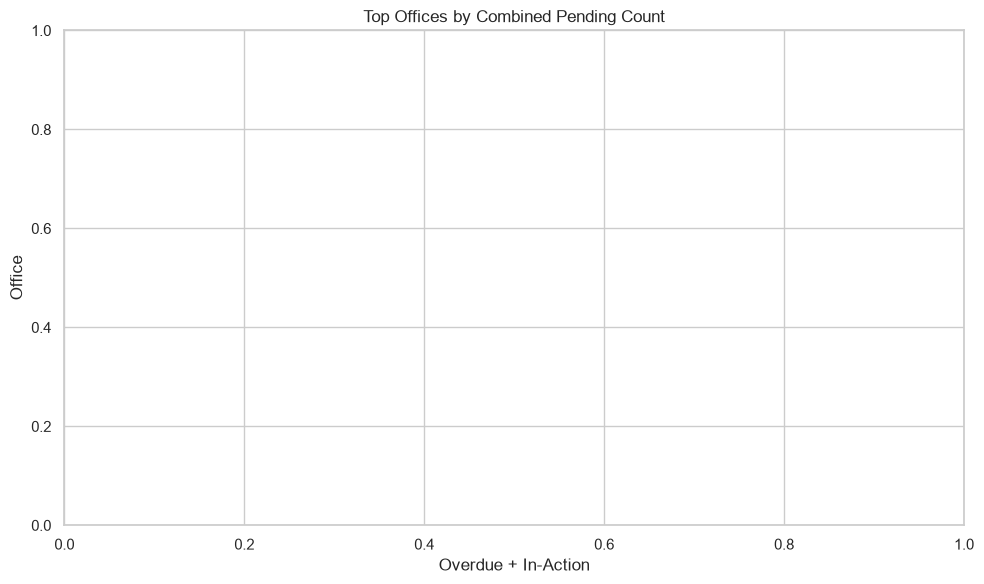

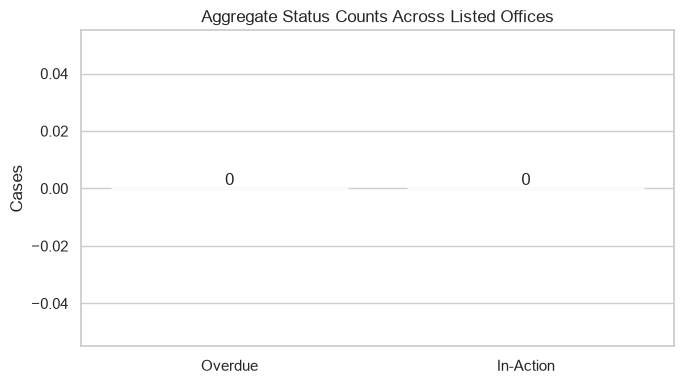

In [24]:
top_offices = detail.sort_values("Total_Pending", ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=top_offices, y="Office", x="Total_Pending", color="#2878A5")
plt.title("Top Offices by Combined Pending Count")
plt.xlabel("Overdue + In-Action")
plt.ylabel("Office")
plt.tight_layout()
plt.show()

status_totals = pd.Series({
    "Overdue": int(detail["Overdue"].sum()),
    "In-Action": int(detail["In_Action"].sum())
})
plt.figure(figsize=(7, 4))
sns.barplot(x=status_totals.index, y=status_totals.values, color="#3A8D75")
plt.title("Aggregate Status Counts Across Listed Offices")
plt.ylabel("Cases")
plt.xlabel("")
for i, value in enumerate(status_totals.values):
    plt.text(i, value, str(value), ha="center", va="bottom")
plt.tight_layout()
plt.show()

In [25]:
priority = detail.copy()
priority = priority.sort_values(
    ["Overdue", "Total_Pending", "In_Action"],
    ascending=[False, False, False]
).reset_index(drop=True)
priority.insert(0, "Follow_Up_Rank", np.arange(1, len(priority) + 1))

def follow_up_band(row):
    if row["Overdue"] > 0:
        return "Overdue cases present — priority follow-up"
    if row["In_Action"] > 0:
        return "In-action cases — monitor progress"
    return "No pending count reported"

priority["Administrative_Follow_Up"] = priority.apply(follow_up_band, axis=1)

display(priority[[
    "Follow_Up_Rank", "Office", "Overdue", "In_Action",
    "Total_Pending", "Overdue_Share_Pct", "Administrative_Follow_Up"
]])

print("Highest overdue count:", int(priority["Overdue"].max()))
print("Offices with overdue cases:", int((priority["Overdue"] > 0).sum()))

KeyError: "['Overdue_Share_Pct'] not in index"

In [26]:
import numpy as np

if "Total_Pending" not in detail.columns:
    detail["Total_Pending"] = detail["Overdue"] + detail["In_Action"]

if "Overdue_Share_Pct" not in detail.columns:
    detail["Overdue_Share_Pct"] = np.where(
        detail["Total_Pending"] > 0,
        100 * detail["Overdue"] / detail["Total_Pending"],
        0.0
    )

priority = detail.copy()
priority = priority.sort_values(
    ["Overdue", "Total_Pending", "In_Action"],
    ascending=[False, False, False]
).reset_index(drop=True)
priority.insert(0, "Follow_Up_Rank", np.arange(1, len(priority) + 1))

def follow_up_band(row):
    if row["Overdue"] > 0:
        return "Overdue cases present — priority follow-up"
    if row["In_Action"] > 0:
        return "In-action cases — monitor progress"
    return "No pending count reported"

priority["Administrative_Follow_Up"] = priority.apply(follow_up_band, axis=1)

cols_to_show = [
    "Follow_Up_Rank", "Office", "Overdue", "In_Action",
    "Total_Pending", "Overdue_Share_Pct", "Administrative_Follow_Up"
]
display(priority[cols_to_show])

print("Highest overdue count:", int(priority["Overdue"].max()))
print("Offices with overdue cases:", int((priority["Overdue"] > 0).sum()))

,Follow_Up_Rank,Office,Overdue,In_Action,Total_Pending,Overdue_Share_Pct,Administrative_Follow_Up


ValueError: cannot convert float NaN to integer

In [27]:
import numpy as np
import pandas as pd

# Fallback if detail is empty or missing expected columns
if "detail" not in globals() or detail.empty:
    # Find columns with at least 2 numeric values
    numeric_cols = [
        col for col in raw.columns
        if pd.to_numeric(raw[col], errors="coerce").notna().sum() >= 2
    ]
    # Pick a text column before the first numeric column as Office
    first_num_col = numeric_cols[0] if numeric_cols else 1
    text_candidates = [
        c for c in range(first_num_col)
        if raw[c].notna().sum() >= 2
    ]
    office_col = text_candidates[-1] if text_candidates else 0

    overdue_col = numeric_cols[0] if len(numeric_cols) >= 1 else 1
    in_action_col = numeric_cols[1] if len(numeric_cols) >= 2 else overdue_col

    detail = pd.DataFrame({
        "Office": raw[office_col].astype(str).str.strip(),
        "Overdue": pd.to_numeric(raw[overdue_col], errors="coerce"),
        "In_Action": pd.to_numeric(raw[in_action_col], errors="coerce"),
    })
    detail = detail[
        detail["Office"].notna()
        & detail["Office"].str.lower().ne("nan")
        & detail["Office"].ne("")
    ].dropna(subset=["Overdue", "In_Action"]).copy()
    detail[["Overdue", "In_Action"]] = detail[["Overdue", "In_Action"]].astype(int)

detail["Total_Pending"] = detail["Overdue"] + detail["In_Action"]
detail["Overdue_Share_Pct"] = np.where(
    detail["Total_Pending"] > 0,
    100 * detail["Overdue"] / detail["Total_Pending"],
    0.0
).round(1)

priority = detail.sort_values(
    ["Overdue", "Total_Pending", "In_Action"],
    ascending=[False, False, False]
).reset_index(drop=True)
priority.insert(0, "Follow_Up_Rank", np.arange(1, len(priority) + 1))

def follow_up_band(row):
    if row["Overdue"] > 0:
        return "Overdue cases present — priority follow-up"
    if row["In_Action"] > 0:
        return "In-action cases — monitor progress"
    return "No pending count reported"

priority["Administrative_Follow_Up"] = priority.apply(follow_up_band, axis=1)

cols_to_show = [
    "Follow_Up_Rank", "Office", "Overdue", "In_Action",
    "Total_Pending", "Overdue_Share_Pct", "Administrative_Follow_Up"
]
display(priority[cols_to_show])

max_overdue = priority["Overdue"].max()
print("Highest overdue count:", 0 if pd.isna(max_overdue) else int(max_overdue))
print("Offices with overdue cases:", int((priority["Overdue"] > 0).sum()))

,Follow_Up_Rank,Office,Overdue,In_Action,Total_Pending,Overdue_Share_Pct,Administrative_Follow_Up
0,1,43,43,9255620488,9255620531,0.0,Overdue cases present — priority follow-up
1,2,42,42,9991557638,9991557680,0.0,Overdue cases present — priority follow-up
2,3,41,41,9671110059,9671110100,0.0,Overdue cases present — priority follow-up
3,4,40,40,9991063630,9991063670,0.0,Overdue cases present — priority follow-up
4,5,39,39,9354730529,9354730568,0.0,Overdue cases present — priority follow-up
5,6,38,38,9671353283,9671353321,0.0,Overdue cases present — priority follow-up
6,7,37,37,9896365079,9896365116,0.0,Overdue cases present — priority follow-up
7,8,36,36,9812083584,9812083620,0.0,Overdue cases present — priority follow-up
8,9,35,35,9896232104,9896232139,0.0,Overdue cases present — priority follow-up
9,10,34,34,8527505879,8527505913,0.0,Overdue cases present — priority follow-up


Highest overdue count: 43
Offices with overdue cases: 43


In [28]:
def build_officer_brief(top_k=5):
    top_rows = priority.head(int(top_k))
    lines = [
        "JAN-SAMADHAN — CM WINDOW PENDENCY MONITORING BRIEF",
        "Source snapshot: 18 November 2026",
        "",
        f"Office-wise aggregate: {total_combined:,} cases "
        f"({total_overdue:,} overdue; {total_in_action:,} in-action).",
        "",
        f"Top {len(top_rows)} offices by overdue-first follow-up rule:"
    ]
    for _, row in top_rows.iterrows():
        lines.append(
            f"- {row['Office']}: {int(row['Overdue'])} overdue; "
            f"{int(row['In_Action'])} in-action; {int(row['Total_Pending'])} combined."
        )
    lines += [
        "",
        "Suggested verification actions:",
        "1. Obtain case-level status and reasons for delay from offices with overdue cases.",
        "2. Review pending cases with the concerned nodal officers and record the next action.",
        "3. Update the official system only after checking the underlying case records.",
        "4. Escalate inter-departmental matters through the prescribed administrative channel.",
        "",
        "Limitation: The supplied workbook contains aggregate counts only; it does not provide "
        "individual complaint details, filing dates, citizen identifiers, or prescribed SLA timelines."
    ]
    return "\n".join(lines)

brief_box = None
try:
    import ipywidgets as widgets
    from IPython.display import display
    brief_count = widgets.IntSlider(value=5, min=1, max=min(15, len(priority)), description="Top offices:")
    brief_button = widgets.Button(description="Generate officer brief", button_style="primary")
    brief_output = widgets.Output()
    def show_brief(_):
        with brief_output:
            brief_output.clear_output()
            print(build_officer_brief(brief_count.value))
    brief_button.on_click(show_brief)
    display(widgets.VBox([brief_count, brief_button, brief_output]))
except Exception:
    print(build_officer_brief(5))

def answer_officer_query(question):
    q = str(question).lower()
    if any(word in q for word in ["total", "overall", "aggregate"]):
        return f"Office-wise aggregate: {total_combined} cases ({total_overdue} overdue; {total_in_action} in-action)."
    if "overdue" in q and any(word in q for word in ["top", "highest", "office"]):
        row = priority.iloc[0]
        return f"Highest overdue count: {row['Office']} ({int(row['Overdue'])} overdue)."
    if "nodal" in q and not nodal.empty:
        return nodal.sort_values("Total_Pending", ascending=False).to_string(index=False)
    if any(word in q for word in ["office", "rank", "priority"]):
        return priority[["Follow_Up_Rank", "Office", "Overdue", "In_Action", "Total_Pending"]].head(10).to_string(index=False)
    return ("Available source fields: office-wise overdue and in-action counts, plus a separate "
            "nodal-officer pendency summary. Individual complaint details and delay reasons are not present.")

try:
    q_input = widgets.Text(placeholder="Ask: Which office has the highest overdue count?", description="Question:", layout=widgets.Layout(width="80%"))
    q_button = widgets.Button(description="Ask")
    q_output = widgets.Output()
    def run_question(_):
        with q_output:
            q_output.clear_output()
            print(answer_officer_query(q_input.value))
    q_button.on_click(run_question)
    display(widgets.VBox([widgets.HBox([q_input, q_button]), q_output]))
except Exception:
    print(answer_officer_query("Which office has the highest overdue count?"))

In [29]:
def answer_officer_query(question: str) -> str:
    q = str(question).lower()
    if any(term in q for term in ["total", "overall", "aggregate"]):
        return (
            f"Listed office-wise aggregate: {total_combined} cases; "
            f"{total_overdue} overdue and {total_in_action} in-action."
        )
    if "overdue" in q and ("top" in q or "highest" in q or "office" in q):
        row = priority.iloc[0]
        return (
            f"Highest overdue count in the listed office-wise table: {row['Office']} "
            f"({int(row['Overdue'])} overdue cases)."
        )
    if "nodal" in q and not nodal.empty:
        return nodal.sort_values("Total_Pending", ascending=False).to_string(index=False)
    return (
        "The workbook supports office-wise overdue/in-action counts and a nodal-officer "
        "pendency summary only. Please consult the case-level CM Window register for "
        "individual complaint details, reasons, dates, or SLA information."
    )

print(answer_officer_query("Which office has the highest overdue count?"))

Highest overdue count in the listed office-wise table: 43 (43 overdue cases).
